# P01 — Gotas vazias a partir da matriz raw

## Pergunta

A matriz filtrada do Cell Ranger deixa de fora alguma célula que valha a
pena recuperar? Esta etapa parte da matriz **raw** (`raw_feature_bc_matrix.h5`,
todos os barcodes) e refaz a separação entre gotas com célula e gotas vazias
com os métodos que o capítulo *raw data processing* do
[sc-best-practices](https://www.sc-best-practices.org/introduction/raw-data-processing/)
cita: o knee plot e o `emptyDrops` / `emptyDropsCellRanger` do DropletUtils.
O CellBender, a segunda opinião, está em P02.

## O que o capítulo pede e o que dá para fazer aqui

Não há FASTQ nem BAM destas corridas. As etapas anteriores à matriz —
controle de qualidade das leituras, alinhamento, correção de barcode e
resolução de UMI — foram feitas pelo Cell Ranger 10.1.0 e só podem ser
auditadas pelo que ele registrou (seção 1).

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import time
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

from functions import bpqc, config, droplets, fmt as F, io, plotting, qcplots
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "P01_gotas_vazias"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
FDR = config.EMPTYDROPS_FDR
PAINEIS = {"T": config.MARKERS_T, "B": config.MARKERS_B, "mieloide": config.MARKERS_MYELOID,
           "eritroide": config.MARKERS_ERYTHROID, "plaqueta": ["PPBP", "PF4", "GP9", "ITGA2B", "TUBB1"]}

## 1. As etapas anteriores à matriz (checklist do capítulo)

In [2]:
met = pd.read_csv(config.TABLES / "C01_websummary_metricas" / "metricas_por_biblioteca.csv", index_col=0).reindex(LIBS)
supp = pd.read_csv(config.TABLES / "C03_rarefacao_citocinas" / "testes_de_artefato.csv", index_col=0).reindex(LIBS)


def faixa(s, pct=True, nd=1):
    f = (lambda v: F.pct(v, nd)) if pct else (lambda v: F.f(v, nd))
    return f"{f(s.min())} – {f(s.max())}"


check = pd.DataFrame([
    ["QC das leituras (FastQC)", "não refeito — sem FASTQ",
     f"Q30: barcode {faixa(met['q30_barcode'])}, UMI {faixa(met['q30_umi'])}, RNA {faixa(met['q30_rna'])}", "C01"],
    ["alinhamento ao genoma", "Cell Ranger 10.1.0 (STAR), GRCh38-2024-A, íntrons incluídos",
     f"mapeados no genoma {faixa(met['mapeados_genoma'])}; no transcriptoma {faixa(met['conf_transcriptoma'])}; "
     f"antisense {faixa(met['antisense'])}", "C01"],
    ["correção de barcode (lista de permissão)", "Cell Ranger, distância de Hamming 1",
     f"barcodes válidos {faixa(met['barcodes_validos'])}", "C01"],
    ["resolução de UMI", "Cell Ranger, distância 1 entre UMIs do mesmo gene",
     f"UMIs válidos {faixa(met['umis_validos'])}; erros de UMI explicam {faixa(supp['baixo_suporte_explicado_por_umi'], nd=0)} "
     "das moléculas de 1–2 reads", "C01, C03"],
    ["gotas vazias", "Cell Ranger: OrdMag + teste tipo EmptyDrops, com piso de 500 UMIs", "refeito aqui e em P02", "P01, P02"],
    ["RNA ambiente", "não corrigido pelo Cell Ranger", "SoupX e CellBender", "P02, P04"],
    ["doublets", "não tratado pelo Cell Ranger", "scDblFinder (e Scrublet, Solo, cxds em A03/A06)", "P04"],
], columns=["etapa do capítulo", "o que foi feito", "evidência disponível", "onde"]).set_index("etapa do capítulo")
io.save_table(check, NB, "checklist_raw_data", description="Etapas do capítulo raw data processing e o que pode ser avaliado sem FASTQ/BAM")
with pd.option_context("display.max_colwidth", None):
    display(check)

,o que foi feito,evidência disponível,onde
etapa do capítulo,,,
QC das leituras (FastQC),não refeito — sem FASTQ,"Q30: barcode 97,4% – 97,8%, UMI 97,9% – 98,2%, RNA 95,0% – 97,5%",C01
alinhamento ao genoma,"Cell Ranger 10.1.0 (STAR), GRCh38-2024-A, íntrons incluídos","mapeados no genoma 87,9% – 98,3%; no transcriptoma 62,3% – 82,2%; antisense 9,5% – 22,2%",C01
correção de barcode (lista de permissão),"Cell Ranger, distância de Hamming 1","barcodes válidos 93,9% – 97,4%",C01
resolução de UMI,"Cell Ranger, distância 1 entre UMIs do mesmo gene","UMIs válidos 96,1% – 96,6%; erros de UMI explicam 0% – 21% das moléculas de 1–2 reads","C01, C03"
gotas vazias,"Cell Ranger: OrdMag + teste tipo EmptyDrops, com piso de 500 UMIs",refeito aqui e em P02,"P01, P02"
RNA ambiente,não corrigido pelo Cell Ranger,SoupX e CellBender,"P02, P04"
doublets,não tratado pelo Cell Ranger,"scDblFinder (e Scrublet, Solo, cxds em A03/A06)",P04


## 2. emptyDrops e emptyDropsCellRanger

Por biblioteca, com os parâmetros do DropletUtils:

* `barcodeRanks` — knee e inflexão da curva de UMIs por posto;
* `emptyDrops(lower = 100, niters = 10.000)` — os barcodes com até 100 UMIs
  definem o perfil ambiente; cada barcode acima disso é testado contra esse
  perfil (multinomial de Dirichlet, p-valor por Monte Carlo); os acima do
  knee entram direto. Chamada: FDR ≤ 0,001;
* `emptyDropsCellRanger` — a versão que imita o Cell Ranger, inclusive o piso
  de 500 UMIs. Serve de controle: tem de reproduzir a chamada do Cell Ranger.

Os resultados ficam em `HEAVY_OUT/emptydrops/<biblioteca>/` e só rodam de
novo se faltarem.

In [3]:
t0 = time.time()
for lib in LIBS:
    droplets.run_emptydrops(lib)
print(f"DropletUtils pronto para as {len(LIBS)} bibliotecas em {time.time() - t0:.0f} s")

DropletUtils pronto para as 14 bibliotecas em 0 s


In [4]:
mb = io.load_data("C03_rarefacao_citocinas", "mol_barcodes")
mb = mb.set_index(mb["library_id"] + "|" + mb["barcode"])["frac_intronica"]

linhas, cand, curvas, semel, controles = [], [], {}, [], []
for lib in LIBS:
    raw = io.read_raw(lib)
    cr = set(io.read_filtered(lib)["barcodes"])
    ed = droplets.read_emptydrops(lib)
    tot = np.asarray(raw["X"].sum(axis=1)).ravel()
    bc = raw["barcodes"]
    is_cr = pd.Index(bc).isin(cr)
    e = ed["emptydrops"].set_index("barcode")
    c = ed["edcr"].set_index("barcode")
    ed_call = pd.Index(bc).isin(set(e.index[e["fdr"] <= FDR]))
    edcr_call = pd.Index(bc).isin(set(c.index[c["fdr"] <= FDR]))
    rec = ed_call & ~is_cr
    curvas[lib] = {"tot": tot, "cr": is_cr, "rec": rec, "knee": ed["knee"], "inflection": ed["inflection"]}
    lim = e[(e["limited"]) & (e["fdr"] > FDR)]
    linhas.append({
        "library_id": lib, "barcodes_com_umi": int((tot > 0).sum()), "celulas_cellranger": int(is_cr.sum()),
        "knee": ed["knee"], "inflexao": ed["inflection"],
        "testados_emptydrops": len(e), "emptydrops": int(ed_call.sum()),
        "emptydrops_e_cellranger": int((ed_call & is_cr).sum()),
        "cellranger_nao_chamadas_pelo_emptydrops": int((is_cr & ~ed_call).sum()),
        "recuperados": int(rec.sum()),
        "emptydrops_cellranger": int(edcr_call.sum()), "edcr_igual_cellranger": int((edcr_call & is_cr).sum()),
        "limited_acima_do_fdr": len(lim),
    })
    # tabela de candidatos: Cell Ranger ∪ emptyDrops
    keep = np.flatnonzero(is_cr | ed_call | (tot >= config.EMPTYDROPS_LOWER))   # todos os barcodes ≥ 100 UMIs
    X = raw["X"][keep]
    nomes = raw["gene_names"]
    mt = np.char.startswith(nomes.astype(str), "MT-")
    umis = np.asarray(X.sum(axis=1)).ravel()
    genes = np.asarray((X > 0).sum(axis=1)).ravel()
    amb = ed["ambiente"].set_index("gene")["prop"].reindex(raw["gene_ids"]).fillna(0).to_numpy()
    lk = droplets.cell_likeness(raw["X"], tot, is_cr, np.flatnonzero(rec))
    llr_all = np.asarray(X @ lk["lr"]).ravel() / np.maximum(umis, 1)
    semel.append({"library_id": lib, "recuperados": int(rec.sum()), "acima_do_limiar": lk["acima"],
                  "estimativa_com_perfil_de_celula": lk["n_semelhantes"], "sensibilidade_do_teste": lk["sensibilidade"],
                  "falsos_positivos_do_teste": lk["fp"], "limiar": lk["limiar"],
                  "llr_mediana_recuperados": float(np.median(lk["llr"])) if len(lk["llr"]) else np.nan,
                  "llr_mediana_celulas_reduzidas": float(np.median(lk["llr_celulas_reduzidas"])) if len(lk["llr"]) else np.nan,
                  "llr_mediana_vazias": float(np.median(lk["llr_vazias"])) if len(lk["llr"]) else np.nan})
    for nome, v in (("células reais reduzidas", lk["llr_celulas_reduzidas"]), ("gotas vazias somadas", lk["llr_vazias"]),
                    ("recuperados", lk["llr"])):
        controles.append(pd.DataFrame({"library_id": lib, "grupo": nome, "llr_rel": v - lk["limiar"]}))
    ls = bpqc.lineage_scores(X, nomes, PAINEIS)
    df = pd.DataFrame({
        "library_id": lib, "barcode": bc[keep], "cellranger": is_cr[keep], "emptydrops": ed_call[keep],
        "emptydrops_cellranger": edcr_call[keep],
        "fdr_emptydrops": e["fdr"].reindex(bc[keep]).to_numpy(),
        "umis": umis, "genes": genes, "pct_mt": np.asarray(X[:, mt].sum(axis=1)).ravel() / np.maximum(umis, 1) * 100,
        "llr": llr_all, "limiar_llr": lk["limiar"],
    })
    for k in PAINEIS:
        df[f"frac_{k}"] = ls[k].to_numpy()
    cand.append(df)
    del raw, X
resumo = pd.DataFrame(linhas).set_index("library_id")
cand = pd.concat(cand, ignore_index=True)
cand["cell_key"] = cand["library_id"] + "|" + cand["barcode"]
cand["frac_intronica"] = mb.reindex(cand["cell_key"]).to_numpy()
assert cand["frac_intronica"].notna().all(), "fração intrônica ausente para algum candidato"
cand["recuperado"] = cand["emptydrops"] & ~cand["cellranger"]
cand["parece_celula"] = cand["llr"] > cand["limiar_llr"]
semel = pd.DataFrame(semel).set_index("library_id")
controles = pd.concat(controles, ignore_index=True)
io.save_table(resumo, NB, "chamadas_por_biblioteca", description="Cell Ranger × emptyDrops × emptyDropsCellRanger, por biblioteca")
io.save_table(semel, NB, "semelhanca_com_celulas",
              description="Recuperados com perfil de célula: teste com controles de profundidade, por biblioteca")
print(f"{F.n(len(cand))} barcodes com ≥ 100 UMIs ou chamados; recuperados pelo emptyDrops: {F.n(cand['recuperado'].sum())}; "
      f"células do Cell Ranger que o emptyDrops não chama: {F.n(resumo['cellranger_nao_chamadas_pelo_emptydrops'].sum())}")
print(f"emptyDropsCellRanger reproduz o Cell Ranger em {F.n(resumo['edcr_igual_cellranger'].sum())} de "
      f"{F.n(resumo['celulas_cellranger'].sum())} células; barcodes Limited acima do FDR: {int(resumo['limited_acima_do_fdr'].sum())}")
resumo

88.000 barcodes com ≥ 100 UMIs ou chamados; recuperados pelo emptyDrops: 38.005; células do Cell Ranger que o emptyDrops não chama: 1.334
emptyDropsCellRanger reproduz o Cell Ranger em 37.783 de 37.898 células; barcodes Limited acima do FDR: 0


,barcodes_com_umi,celulas_cellranger,knee,inflexao,testados_emptydrops,emptydrops,emptydrops_e_cellranger,cellranger_nao_chamadas_pelo_emptydrops,recuperados,emptydrops_cellranger,edcr_igual_cellranger,limited_acima_do_fdr
library_id,,,,,,,,,,,,
CTH92_NS,1497038,851,7802.535822,631.145456,967,916,827,24,89,855,851,0
CTH92_ML,1363786,1570,4946.554182,317.579682,1944,1664,1558,12,106,1574,1570,0
CTH94_NS,1668757,6090,9552.345943,1876.848581,9588,6553,5944,146,609,6093,6082,0
CTH94_ML,1204510,547,8578.193902,1420.045340,870,645,540,7,105,548,547,0
CTH97_NS,1271948,1628,6522.114174,1009.748142,6765,6729,1613,15,5116,1628,1627,0
CTH97_ML,890760,4737,2090.142555,319.603978,5697,4866,4372,365,494,4728,4721,0
PB20_NS,1040305,635,8122.466870,547.409146,785,667,581,54,86,655,635,0
PB20_ML,1072778,841,8395.973417,1374.998688,993,942,816,25,126,843,841,0
PB21_NS,1577066,4266,7487.543206,1775.584673,25687,25612,4224,42,21388,4262,4262,0


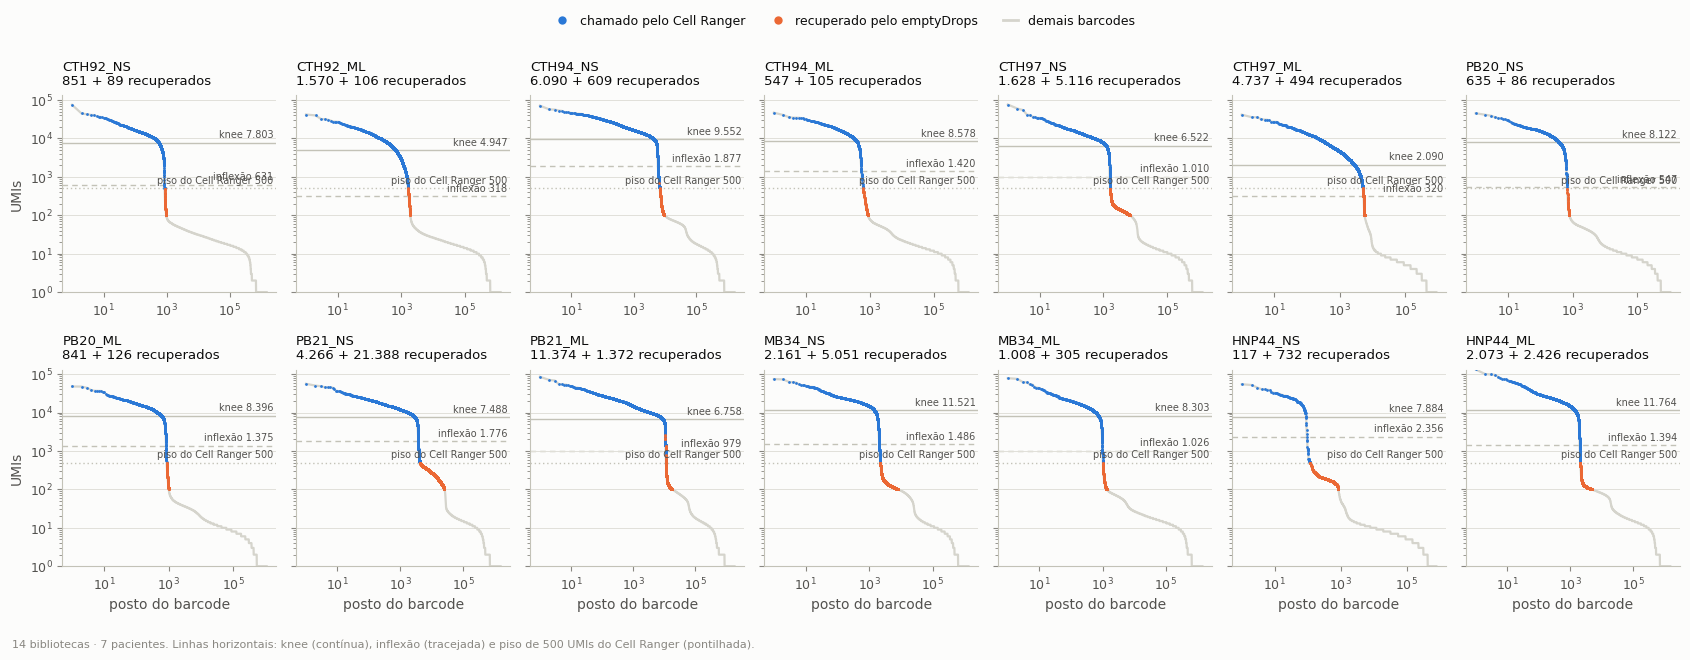

In [5]:
fig, axes = plt.subplots(2, 7, figsize=(17, 6.2), sharey=True)
for ax, lib in zip(axes.ravel(), LIBS):
    c = curvas[lib]
    qcplots.barcode_rank(ax, c["tot"], c["cr"], c["rec"], knee=c["knee"], inflection=c["inflection"],
                         title=f"{lib}\n{F.n(c['cr'].sum())} + {F.n(c['rec'].sum())} recuperados")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_ylim(1, None)
for ax in axes[:, 0]:
    ax.set_ylabel("UMIs")
for ax in axes[1]:
    ax.set_xlabel("posto do barcode")
fig.legend(handles=[mpl.lines.Line2D([], [], marker="o", ls="", ms=6, mfc=col, mec="none", label=lab)
                    for lab, col in [("chamado pelo Cell Ranger", qcplots.CALL_COLORS["Cell Ranger"]),
                                     ("recuperado pelo emptyDrops", qcplots.CALL_COLORS["recuperado"])]]
           + [mpl.lines.Line2D([], [], color=plotting.CONTEXT, lw=2, label="demais barcodes")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
plotting.note(fig, f"{plotting.N_DESIGN}. Linhas horizontais: knee (contínua), inflexão (tracejada) e piso de 500 UMIs do "
                   "Cell Ranger (pontilhada).", y=0.0)
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
plotting.savefig(fig, NB, "knee_plots", description="Knee plot por biblioteca com as chamadas do Cell Ranger e do emptyDrops",
                 data=resumo.reset_index(), data_index=False)
plt.show()

## 3. O que são os barcodes recuperados

O emptyDrops chama tudo o que difere do perfil ambiente — inclusive material
de células mortas, que também difere. Cinco medidas separam uma coisa da
outra:

* **fração intrônica** — material nuclear (de células que perderam o
  citoplasma) tem mais transcritos não processados; o limite é a mediana +
  5 MADs das células do Cell Ranger da mesma biblioteca;
* **UMIs e genes** — quanto material há;
* **% mitocondrial** — células danificadas;
* **perfil de célula ou de ambiente** — log-razão de verossimilhança por UMI
  entre o perfil somado das células e o das gotas vazias (1–100 UMIs). Pouco
  RNA deixa a medida mais ruidosa, então ela vem com dois controles na mesma
  profundidade dos barcodes testados: células reais subamostradas (positivo)
  e gotas vazias somadas (negativo). O limiar deixa passar 1% do controle
  negativo, e a estimativa de quantos recuperados têm perfil de célula
  corrige pela sensibilidade do teste;
* **linhagem** — fração dos UMIs em marcadores de T, B, mieloide, eritroide
  e plaqueta.

In [6]:
cand["intronica_alta"], lim_intr = bpqc.intronic_flag(cand["frac_intronica"], cand["library_id"], cand["cellranger"])
lin = cand[[f"frac_{k}" for k in PAINEIS]]
cand["linhagem"] = np.where(lin.max(axis=1) < 0.002, "sem marcador", lin.idxmax(axis=1).str.replace("frac_", ""))
grp = np.select([cand["cellranger"], cand["recuperado"] & cand["intronica_alta"], cand["recuperado"]],
                ["Cell Ranger", "recuperado · nuclear", "recuperado · citoplasmático"], "outro")
cand["grupo"] = grp
car = cand[cand["grupo"] != "outro"].groupby("grupo").agg(
    barcodes=("umis", "size"), umis_medianos=("umis", "median"), genes_medianos=("genes", "median"),
    pct_mt_mediana=("pct_mt", "median"), intronica_mediana=("frac_intronica", "median"),
    llr_mediana=("llr", "median"), com_perfil_de_celula=("parece_celula", "mean"))
car = car.reindex(["Cell Ranger", "recuperado · citoplasmático", "recuperado · nuclear"])
lin_tab = pd.crosstab(cand["grupo"], cand["linhagem"], normalize="index").reindex(car.index)
por_lib = pd.crosstab(cand.loc[cand["recuperado"], "library_id"], cand.loc[cand["recuperado"], "grupo"]).reindex(LIBS).fillna(0).astype(int)
por_lib["células do Cell Ranger"] = resumo["celulas_cellranger"]
io.save_table(car, NB, "recuperados_perfil", description="Perfil dos barcodes recuperados pelo emptyDrops × células do Cell Ranger")
io.save_table(lin_tab, NB, "recuperados_linhagem", description="Linhagem predominante por grupo de barcodes")
io.save_table(por_lib, NB, "recuperados_por_biblioteca", description="Barcodes recuperados por biblioteca, nucleares × citoplasmáticos")
display(car.round(3))
display(semel.round(3))
display(lin_tab.round(3))
por_lib

,barcodes,umis_medianos,genes_medianos,pct_mt_mediana,intronica_mediana,llr_mediana,com_perfil_de_celula
grupo,,,,,,,
Cell Ranger,37898,9119.0,2795.0,3.146,0.232,0.117,0.751
recuperado · citoplasmático,19281,128.0,109.0,0.990,0.457,-0.088,0.099
recuperado · nuclear,18724,209.0,161.0,0.752,0.727,-0.076,0.005


,recuperados,acima_do_limiar,estimativa_com_perfil_de_celula,sensibilidade_do_teste,falsos_positivos_do_teste,limiar,llr_mediana_recuperados,llr_mediana_celulas_reduzidas,llr_mediana_vazias
library_id,,,,,,,,,
CTH92_NS,89,69,77.574,0.888,0.01,-0.084,0.121,0.483,-0.382
CTH92_ML,106,97,101.524,0.955,0.01,-0.068,0.420,0.448,-0.301
CTH94_NS,609,231,279.391,0.815,0.01,0.031,-0.002,0.112,-0.099
CTH94_ML,105,26,30.917,0.817,0.01,0.185,0.026,0.556,-0.229
CTH97_NS,5116,86,37.262,0.945,0.01,-0.033,-0.578,0.355,-0.435
CTH97_ML,494,287,482.154,0.595,0.01,0.039,0.065,0.069,-0.097
PB20_NS,86,30,51.943,0.571,0.01,0.184,-0.022,0.293,-0.130
PB20_ML,126,62,105.819,0.584,0.01,0.209,0.192,0.293,-0.062
PB21_NS,21388,331,178.265,0.667,0.01,0.103,-0.054,0.208,-0.204


linhagem,B,T,eritroide,mieloide,plaqueta,sem marcador
grupo,,,,,,
Cell Ranger,0.006,0.707,0.000,0.002,0.000,0.285
recuperado · citoplasmático,0.006,0.275,0.005,0.007,0.003,0.704
recuperado · nuclear,0.009,0.175,0.000,0.003,0.000,0.812


grupo,recuperado · citoplasmático,recuperado · nuclear,células do Cell Ranger
library_id,,,
CTH92_NS,89,0,851
CTH92_ML,106,0,1570
CTH94_NS,608,1,6090
CTH94_ML,105,0,547
CTH97_NS,1514,3602,1628
CTH97_ML,453,41,4737
PB20_NS,86,0,635
PB20_ML,126,0,841
PB21_NS,6348,15040,4266


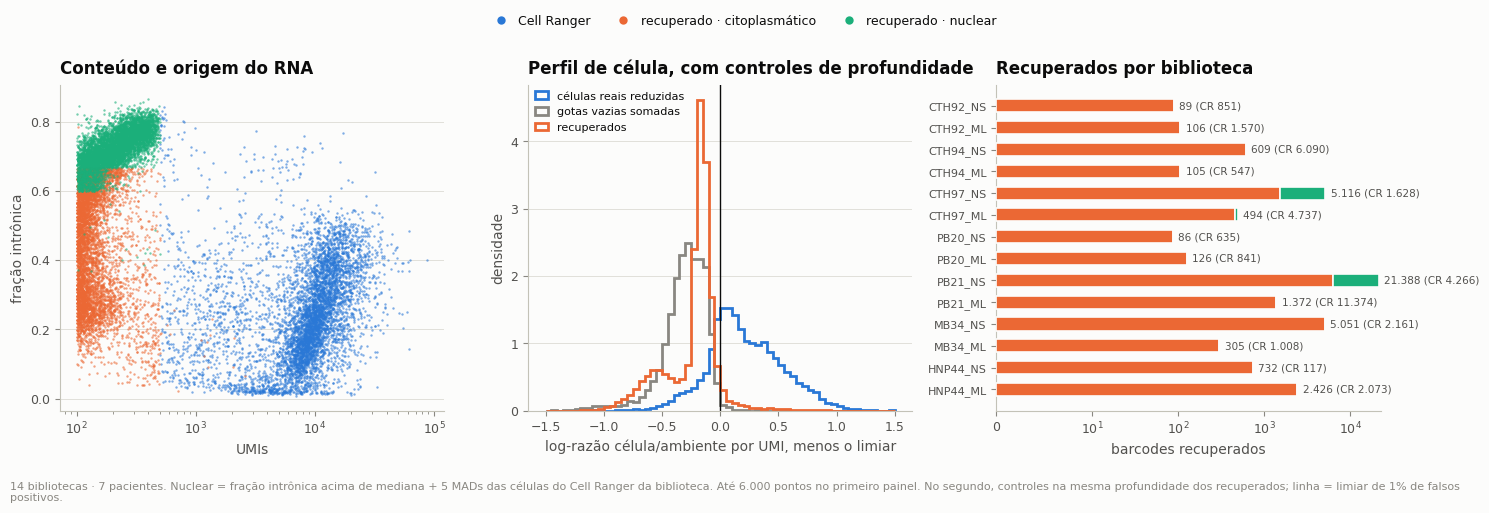

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
cores = {"Cell Ranger": qcplots.CALL_COLORS["Cell Ranger"], "recuperado · citoplasmático": qcplots.CALL_COLORS["recuperado"],
         "recuperado · nuclear": plotting.CATEGORICAL[2]}
sub = cand[cand["grupo"] != "outro"]
rng = np.random.default_rng(0)
ordem = ["Cell Ranger", "recuperado · citoplasmático", "recuperado · nuclear"]
for g in ordem:
    d = sub[sub["grupo"] == g]
    if len(d) > 6000:
        d = d.iloc[rng.choice(len(d), 6000, replace=False)]
    axes[0].scatter(d["umis"], d["frac_intronica"], s=3, color=cores[g], lw=0, alpha=0.6, rasterized=True, label=g)
axes[0].set_xscale("log")
axes[0].set_xlabel("UMIs")
axes[0].set_ylabel("fração intrônica")
axes[0].set_title("Conteúdo e origem do RNA")
bins = np.linspace(-1.5, 1.5, 61)
for nome, cor in [("células reais reduzidas", qcplots.CALL_COLORS["Cell Ranger"]), ("gotas vazias somadas", INK["muted"]),
                  ("recuperados", qcplots.CALL_COLORS["recuperado"])]:
    v = controles.loc[controles["grupo"] == nome, "llr_rel"].clip(-1.5, 1.5)
    axes[1].hist(v, bins=bins, density=True, histtype="step", lw=2, color=cor, label=nome)
axes[1].axvline(0, color=INK["primary"], lw=1)
axes[1].set_xlabel("log-razão célula/ambiente por UMI, menos o limiar")
axes[1].set_ylabel("densidade")
axes[1].set_title("Perfil de célula, com controles de profundidade")
axes[1].legend(loc="upper left", fontsize=8)
y = np.arange(len(LIBS))[::-1]
left = np.zeros(len(LIBS))
for g in ["recuperado · citoplasmático", "recuperado · nuclear"]:
    v = por_lib.get(g, pd.Series(0, index=LIBS)).reindex(LIBS).fillna(0).to_numpy()
    axes[2].barh(y, v, left=left, color=cores[g], edgecolor=INK["surface"], linewidth=1.2, height=0.6, zorder=3)
    left += v
for yi, lib, tot, ncr in zip(y, LIBS, left, por_lib["células do Cell Ranger"]):
    axes[2].annotate(f"{F.n(tot)} (CR {F.n(ncr)})", (tot, yi), xytext=(4, 0), textcoords="offset points", va="center",
                     fontsize=7.5, color=INK["secondary"])
axes[2].set_yticks(y)
axes[2].set_yticklabels(LIBS, fontsize=8)
axes[2].set_xscale("symlog", linthresh=10)
axes[2].set_xlabel("barcodes recuperados")
axes[2].set_title("Recuperados por biblioteca")
axes[2].grid(axis="y", visible=False)
fig.legend(handles=[mpl.lines.Line2D([], [], marker="o", ls="", ms=6, mfc=cores[g], mec="none", label=g) for g in ordem],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
plotting.note(fig, f"{plotting.N_DESIGN}. Nuclear = fração intrônica acima de mediana + 5 MADs das células do Cell Ranger da "
                   "biblioteca. Até 6.000 pontos no primeiro painel. No segundo, controles na mesma profundidade dos recuperados; "
                   "linha = limiar de 1% de falsos positivos.", y=0.0)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
plotting.savefig(fig, NB, "recuperados", description="Barcodes recuperados pelo emptyDrops: conteúdo, perfil e distribuição",
                 data=por_lib.rename_axis("library_id").reset_index(), data_index=False)
plt.show()

In [8]:
io.save_data(cand.drop(columns=["cell_key"]), NB, "candidatos",
             description="Barcodes chamados pelo Cell Ranger ou pelo emptyDrops, com métricas e grupo")
rc = cand[cand["recuperado"]]
print(f"recuperados pelo emptyDrops: {F.n(len(rc))}; nucleares {F.n(rc['intronica_alta'].sum())} "
      f"({F.pct(rc['intronica_alta'].mean(), 0)}); UMIs medianos {F.n(rc['umis'].median())} contra "
      f"{F.n(cand.loc[cand['cellranger'], 'umis'].median())} nas células do Cell Ranger")

[io] conteúdo mudou — nova versão: candidatos__v2.parquet (anterior preservada)
recuperados pelo emptyDrops: 38.005; nucleares 18.724 (49%); UMIs medianos 153 contra 9.119 nas células do Cell Ranger


## Problemas encontrados

In [9]:
nao = resumo["cellranger_nao_chamadas_pelo_emptydrops"]
log.add("MAJOR", "emptyDrops (lower = 100) sobre a matriz raw",
        "o que o emptyDrops acrescenta ao Cell Ranger é, em quase tudo, material de baixo conteúdo, não células",
        evidence=f"{F.n(len(rc))} barcodes recuperados; UMIs medianos {F.n(rc['umis'].median())} e genes medianos "
                 f"{F.n(rc['genes'].median())} (células do Cell Ranger: {F.n(cand.loc[cand['cellranger'], 'umis'].median())} e "
                 f"{F.n(cand.loc[cand['cellranger'], 'genes'].median())}); {F.pct(rc['intronica_alta'].mean(), 0)} com perfil nuclear; "
                 f"com controle de profundidade, só {F.n(semel['acima_do_limiar'].sum())} passam do limiar de 1% de falsos "
                 f"positivos (estimativa de {F.n(semel['estimativa_com_perfil_de_celula'].sum())} com perfil de célula); "
                 f"{F.pct((rc['linhagem'] == 'sem marcador').mean(), 0)} sem sinal de nenhum marcador de linhagem; "
                 f"PB21_NS sozinha tem {F.n(resumo.loc['PB21_NS', 'recuperados'])}",
        impact="o número bruto de 'células' recuperadas não significa ganho; o QC (P03) decide quantas são células",
        recommendation="não usar a chamada do emptyDrops sem o QC; olhar o resultado do QC por origem da chamada")
log.add("MINOR", "células do Cell Ranger que o emptyDrops não chama",
        "parte das células do Cell Ranger não difere do perfil ambiente no teste do emptyDrops",
        evidence=f"{F.n(nao.sum())} células; as maiores contagens em PB21_ML ({F.n(nao['PB21_ML'])}), CTH97_ML ({F.n(nao['CTH97_ML'])}) "
                 f"e CTH94_NS ({F.n(nao['CTH94_NS'])})",
        impact="são células de pouco RNA ou parecidas com o ambiente; ficam como candidatas e passam pelo mesmo QC",
        recommendation="manter como candidatas (a união dos métodos é o ponto de partida do QC)")
log.add("INFO", "emptyDropsCellRanger", "[VERIFICAÇÃO] a versão do DropletUtils que imita o Cell Ranger reproduz a chamada dele",
        evidence=f"{F.n(resumo['edcr_igual_cellranger'].sum())} de {F.n(resumo['celulas_cellranger'].sum())} células; "
                 f"nenhum barcode 'Limited' acima do FDR",
        impact="a ponte com o R e os parâmetros estão corretos; o piso de 500 UMIs é a diferença entre os dois emptyDrops",
        recommendation="nenhuma")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       1
MINOR       1
INFO        1


severity,location,problem,evidence,impact,recommendation
MAJOR,emptyDrops (lower = 100) sobre a matriz raw,"o que o emptyDrops acrescenta ao Cell Ranger é, em quase tudo, material de baixo conteúdo, não células","38.005 barcodes recuperados; UMIs medianos 153 e genes medianos 126 (células do Cell Ranger: 9.119 e 2.795); 49% com perfil nuclear; com controle de profundidade, só 1.999 passam do limiar de 1% de falsos positivos (estimativa de 2.263 com perfil de célula); 76% sem sinal de nenhum marcador de linhagem; PB21_NS sozinha tem 21.388",o número bruto de 'células' recuperadas não significa ganho; o QC (P03) decide quantas são células,não usar a chamada do emptyDrops sem o QC; olhar o resultado do QC por origem da chamada
MINOR,células do Cell Ranger que o emptyDrops não chama,parte das células do Cell Ranger não difere do perfil ambiente no teste do emptyDrops,"1.334 células; as maiores contagens em PB21_ML (495), CTH97_ML (365) e CTH94_NS (146)",são células de pouco RNA ou parecidas com o ambiente; ficam como candidatas e passam pelo mesmo QC,manter como candidatas (a união dos métodos é o ponto de partida do QC)
INFO,emptyDropsCellRanger,[VERIFICAÇÃO] a versão do DropletUtils que imita o Cell Ranger reproduz a chamada dele,37.783 de 37.898 células; nenhum barcode 'Limited' acima do FDR,a ponte com o R e os parâmetros estão corretos; o piso de 500 UMIs é a diferença entre os dois emptyDrops,nenhuma


## Conclusão

O emptyDrops sem o piso de 500 UMIs dobra o número de barcodes
"não vazios", mas o que entra é sobretudo material de baixo conteúdo:
mediana de ~150 UMIs, perfil mais próximo do ambiente que das células,
metade com perfil nuclear, a maioria sem marcador de linhagem e, no teste
com controles de profundidade, perfil de gota vazia — células reais
reduzidas à mesma profundidade continuam reconhecíveis. A maior parte
vem de três bibliotecas não estimuladas com material de células mortas
(PB21_NS, CTH97_NS, MB34_NS). O `emptyDropsCellRanger` reproduz a chamada
do Cell Ranger, de modo que a diferença está no piso de 500 UMIs, não no
método. Quantos desses barcodes são células de fato é decidido no QC (P03).

In [10]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

12 artefatos gravados por este notebook:
                      name    kind
        checklist_raw_data   table
   chamadas_por_biblioteca   table
    semelhanca_com_celulas   table
            fig_knee_plots  figure
            fig_knee_plots   table
        recuperados_perfil   table
      recuperados_linhagem   table
recuperados_por_biblioteca   table
           fig_recuperados  figure
           fig_recuperados   table
                candidatos parquet
                    issues   table
